In [2]:
import os



import warnings
warnings.filterwarnings("ignore")  #  This is the correct way



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys



from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split , GridSearchCV , TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score , precision_score , recall_score, r2_score, f1_score, roc_auc_score, average_precision_score , confusion_matrix , classification_report, precision_recall_curve

In [4]:
import sys

print(f'current env python paths')
print(sys.executable)

current env python paths
c:\Users\adith\anaconda3\python.exe


In [5]:
data = pd.read_csv(r"C:\Users\adith\Downloads\archive (1)\hotel_bookings.csv")
data

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [6]:
data.head()
data.tail()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [7]:
data.shape
data.info

<bound method DataFrame.info of                hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27  

In [8]:
data.isna()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
119386,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
119387,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
119388,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [9]:
print(len(data))

119390


In [10]:
data.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [11]:
missing_counts = data.isna().sum()
missing_values = round(data.isna().mean()*100, (2))

dict = pd.DataFrame({'missing_counts' : missing_counts , 'missing_values' : missing_values })

dict = dict[dict['missing_counts']>0]

def count(nans):
    if nans == 0 : return '0%'
    elif nans <1 : return '1%' 
    elif nans <= 5: return '1-5%'
    elif nans <= 20: return '5-20%'
    elif nans <=50: return '20-50%'
    else:
        return '>50%'

dict['bands'] = dict['missing_values'].apply(count)

print(dict.sort_values(by = 'missing_values', ascending = False))

print(dict['bands'].value_counts())

    



          missing_counts  missing_values  bands
company           112593           94.31   >50%
agent              16340           13.69  5-20%
country              488            0.41     1%
children               4            0.00     0%
bands
0%       1
1%       1
5-20%    1
>50%     1
Name: count, dtype: int64


In [12]:
df = data.drop_duplicates()

In [13]:
df.shape
print(len(df))
print(len(df))

87396
87396


In [14]:
total = len(data)
unique = len(df)
duplicates = total-unique

percentage = (duplicates / total) * 100

print(f'duplicate percentage : {percentage:.2f}%')



duplicate percentage : 26.80%


In [15]:
drop_cols = [
    'is_canceled' , 'reservation_status' , 'reservaton_status_date' , 'booking_changes' , 'assigned_room_type'
]

X = df.drop(columns= drop_cols, errors='ignore')
y = df['is_canceled']





In [16]:
arrival_str = df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'+df['arrival_date_day_of_month'].astype(str)

df['booking_date'] = pd.to_datetime(arrival_str , format= "%Y-%B-%d") - pd.to_timedelta(df['lead_time'] , unit='D')



In [17]:
print(arrival_str)
print(df['booking_date'])

0            2015-July-1
1            2015-July-1
2            2015-July-1
3            2015-July-1
4            2015-July-1
               ...      
119385    2017-August-30
119386    2017-August-31
119387    2017-August-31
119388    2017-August-31
119389    2017-August-29
Length: 87396, dtype: object
0        2014-07-24
1        2013-06-24
2        2015-06-24
3        2015-06-18
4        2015-06-17
            ...    
119385   2017-08-07
119386   2017-05-21
119387   2017-07-28
119388   2017-05-14
119389   2017-02-05
Name: booking_date, Length: 87396, dtype: datetime64[ns]


In [18]:
df = df.sort_values('booking_date'). reset_index(drop=True)

train_end = int(len(df)* 0.70)
val_end = int(len(df)* 0.85)

train_df = df.iloc[ : train_end]
val_df = df.iloc[train_end: val_end]
test_df = df.iloc[val_end:]




In [19]:
target = 'is_canceled'

drop_cols = [
    target, 
    'reservation_status' ,
    'reservation_status_date',
    'assigned_room_type' ,
    'booking_date',
    'booking_changes'
    ]

X_train = train_df.drop(columns= drop_cols , errors='ignore')
y_train = train_df[target]

X_val = val_df.drop(columns = drop_cols , errors='ignore')
y_val = val_df[target]

X_test = test_df.drop(columns= drop_cols, errors = 'ignore')
y_test = test_df[target]





In [20]:
num_cols = X_train.select_dtypes(include=['int64' , 'float64']).columns.to_list()

In [21]:
print(num_cols)
num_cols

['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


['lead_time',
 'arrival_date_year',
 'arrival_date_week_number',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'agent',
 'company',
 'days_in_waiting_list',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests']

In [22]:
cate_cols = X_train.select_dtypes(include=['object']).columns.tolist()

In [23]:
cate_cols

['hotel',
 'arrival_date_month',
 'meal',
 'country',
 'market_segment',
 'distribution_channel',
 'reserved_room_type',
 'deposit_type',
 'customer_type']

In [24]:
X_train = X_train.drop(columns=['company'])
X_val = X_val.drop(columns = ['company'])
X_test = X_test.drop(columns = ['company'])

if 'company' in num_cols:
    num_cols.remove('company')




In [25]:
num_pipe = Pipeline([('imputer' , SimpleImputer(strategy='median')),
                     ('scaler' ,StandardScaler())])

In [26]:
cate_pipe = Pipeline([('imputer' , SimpleImputer(strategy='most_frequent')),
                      ('encoder' , OneHotEncoder(handle_unknown='ignore' , drop = 'first'))])

In [27]:
preprocessed = ColumnTransformer([
    ('num' , num_pipe, num_cols),
    ('cates', cate_pipe , cate_cols)
]

)

In [28]:
print(preprocessed)


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['lead_time', 'arrival_date_year',
                                  'arrival_date_week_number',
                                  'arrival_date_day_of_month',
                                  'stays_in_weekend_nights',
                                  'stays_in_week_nights', 'adults', 'children',
                                  'babies', 'is_repeated_guest',
                                  'previous_cancellations',
                                  'previous...
                                  'days_in_waiting_list', 'adr',
                                  'required_car_parking_spaces',
                                  'total_of_special_requests']),
                                

In [29]:
print(f"train : {train_df['booking_date'].min()} to {train_df['booking_date'].max()}")
print(f"val : {val_df['booking_date'].min()} to {val_df['booking_date'].max()}")
print(f"test : {test_df['booking_date'].min()} to {test_df['booking_date'].max()}")



train : 2013-06-24 00:00:00 to 2016-12-03 00:00:00
val : 2016-12-03 00:00:00 to 2017-02-21 00:00:00
test : 2017-02-21 00:00:00 to 2017-08-31 00:00:00


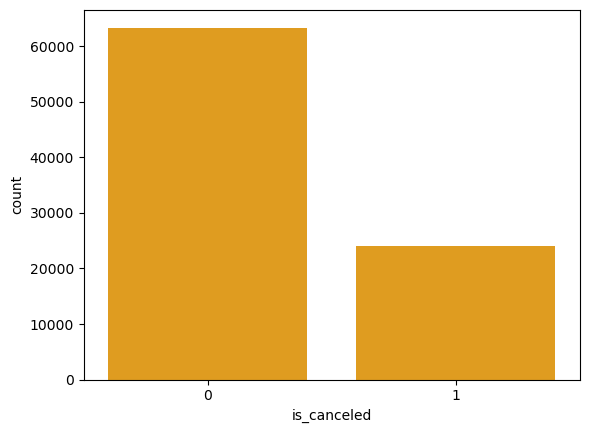

In [30]:
sns.countplot(data = df , x = 'is_canceled', color= 'Orange')
plt.show()

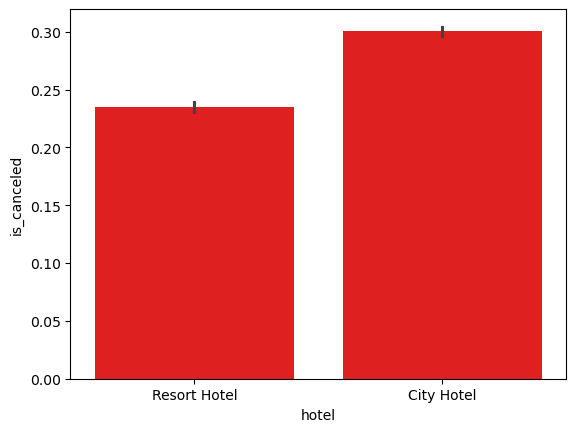

In [31]:
sns.barplot(data = df , x = 'hotel' , y = 'is_canceled', color = 'Red')
plt.show()

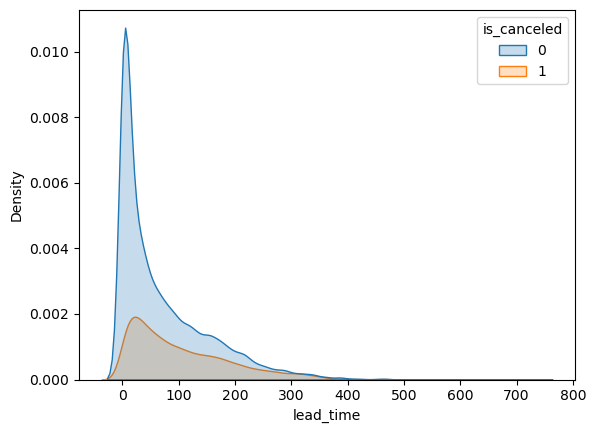

In [32]:
sns.kdeplot(data = df , x = 'lead_time' , hue = 'is_canceled' , fill = True)
plt.show()

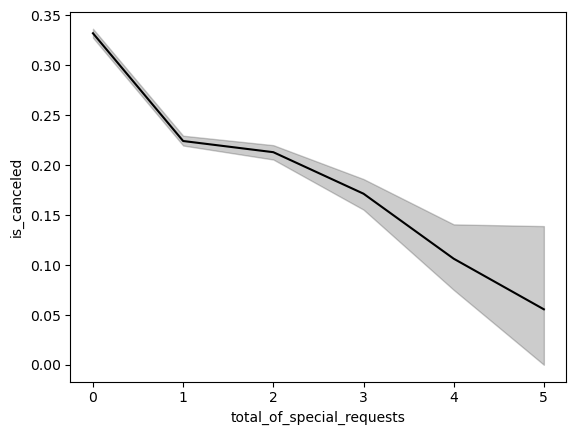

In [33]:
sns.lineplot(data = df , x = 'total_of_special_requests', y = 'is_canceled' , color = 'Black')
plt.show()

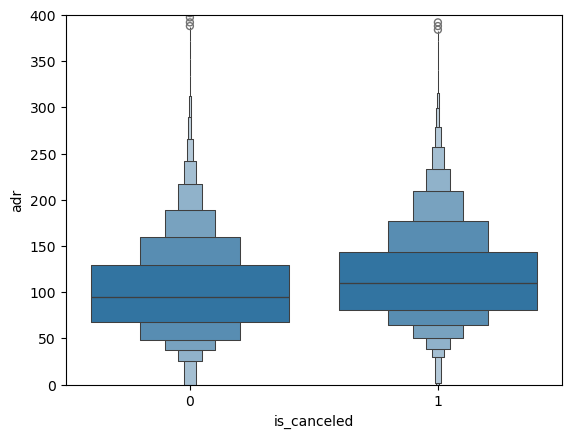

In [34]:
sns.boxenplot(data = df , x = 'is_canceled' , y = 'adr')
plt.ylim(0,400)
plt.show()

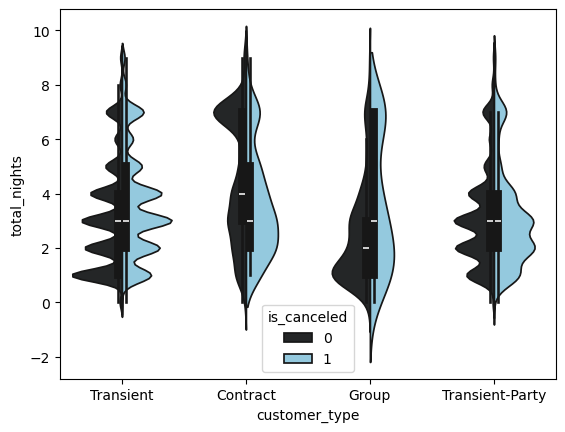

In [35]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

sns.violinplot(
    data = df[df['total_nights']<10],
    x = 'customer_type',
    y = 'total_nights',
    hue = 'is_canceled',
    split = True,
    color=  'SkyBlue'


)
plt.show()

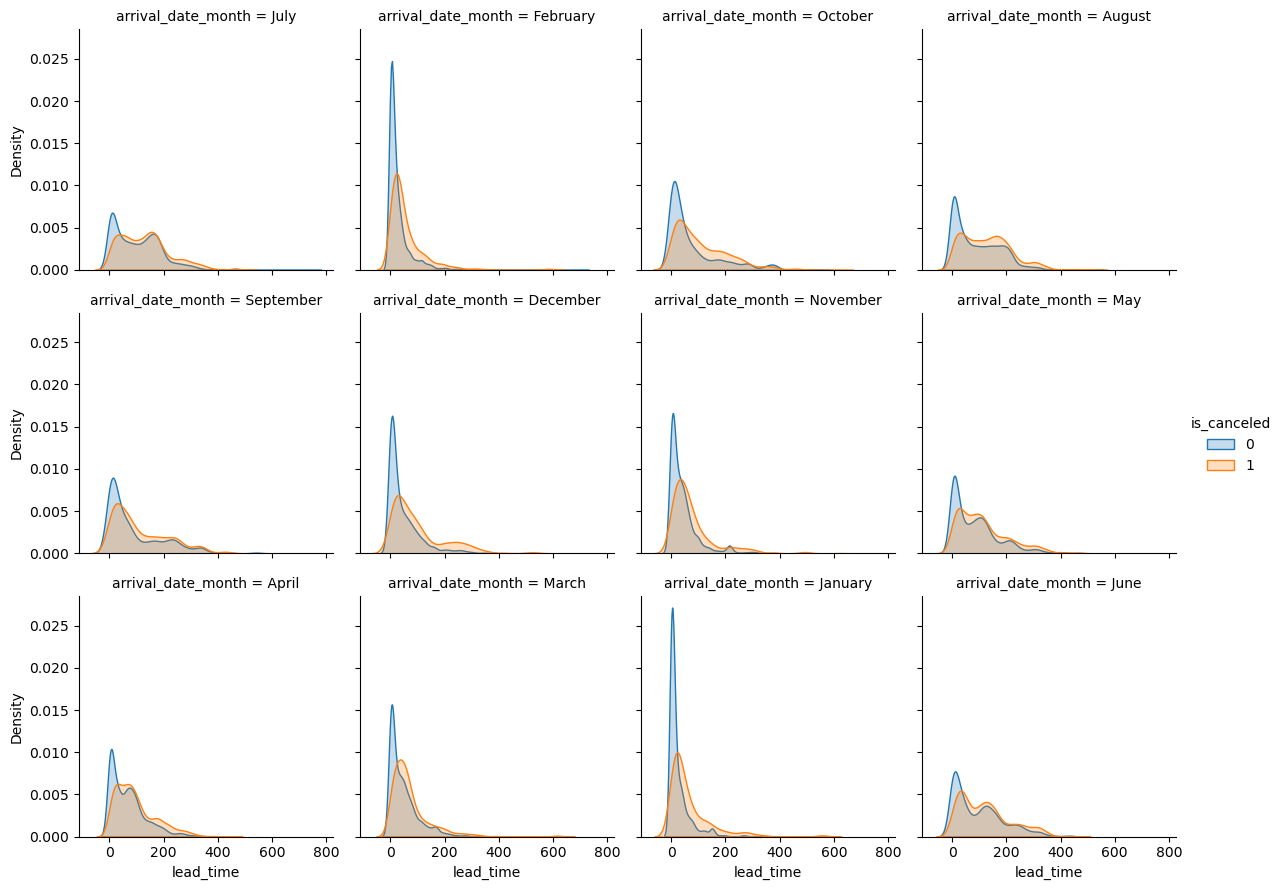

In [36]:
k = sns.FacetGrid( data = df , col = 'arrival_date_month' , col_wrap = 4, hue = 'is_canceled')
k.map(sns.kdeplot , 'lead_time', fill = True)
k.add_legend()
plt.show()

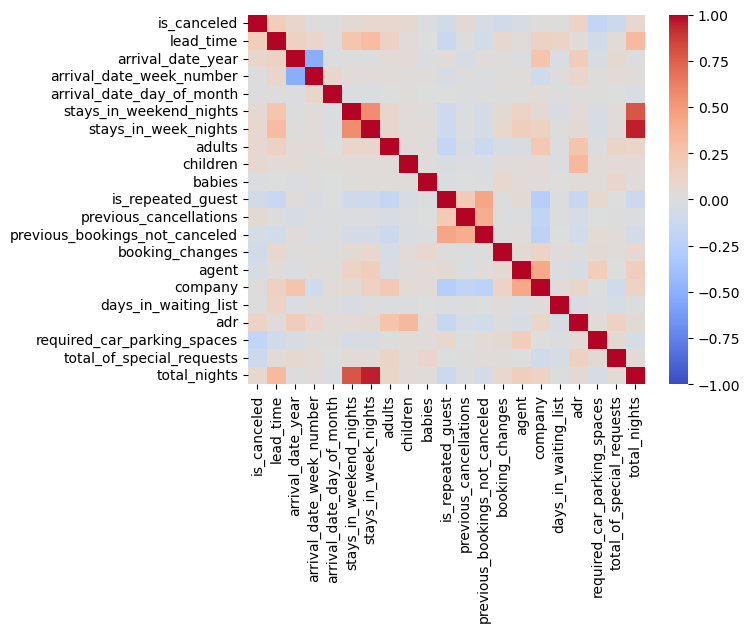

In [37]:
numeric = df.select_dtypes(include=[np.number])

corr_mat = numeric.corr()

sns.heatmap(corr_mat , cmap='coolwarm' , vmin = -1 , vmax = 1)
plt.show()

In [38]:
logisticmodel = Pipeline([
    ("preprocessor" , preprocessed),
    (
        'model' , LogisticRegression(max_iter = 1500 , class_weight='balanced')


    )
])


In [39]:
logisticmodel.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cates', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [40]:
val_proba = logisticmodel.predict_proba(X_val)[:,1]

val_pred = (val_proba >= 0.5).astype(int)

print(val_proba)
print(val_pred)



[0.14330458 0.78631201 0.89316699 ... 0.670057   0.49308316 0.82737441]
[0 1 1 ... 1 0 1]


In [41]:
print('accuracy :' , accuracy_score(y_val, val_pred))
print('precision score : ' , precision_score(y_val , val_pred))
print('recall : ' , recall_score(y_val , val_pred))
print('f1', f1_score(y_val ,val_pred))
print('roc-auc: ', roc_auc_score(y_val , val_proba))
print('pr-auc:', average_precision_score(y_val , val_proba))
print(confusion_matrix(y_val , val_pred))

      

accuracy : 0.6581737737432298
precision score :  0.45351096308631694
recall :  0.8575177118866439
f1 0.5932649541617501
roc-auc:  0.8036623191552636
pr-auc: 0.610762557671215
[[5360 3938]
 [ 543 3268]]


In [42]:
dt_model = Pipeline([
   ( 'preprocessor' , preprocessed),
    (
        'model' , DecisionTreeClassifier(max_depth = 4 , class_weight = 'balanced' , random_state = 43))


])


In [43]:
dt_model.fit(X_train , y_train)



,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cates', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [44]:
dt_val_proba = dt_model.predict_proba(X_val)[:,1]

dt_val_pred = (dt_val_proba >= 0.5).astype(int)



In [45]:
print('accuracy:' , accuracy_score(y_val , dt_val_pred))
print('precision:' , precision_score(y_val , dt_val_pred))
print('recall:' , recall_score(y_val, dt_val_pred))
print('f1score' , f1_score(y_val , dt_val_pred))
print('roc-auc' , roc_auc_score(y_val , dt_val_proba))



accuracy: 0.6396368906857884
precision: 0.44191372948212243
recall: 0.9113093676200472
f1score 0.5952013710368466
roc-auc 0.7458423214682521


In [46]:
rf_model = Pipeline ([
    ('preprocessor' , preprocessed),
    (
        'model' , 
        RandomForestClassifier(
            n_estimators=299,
            n_jobs = -1,
            max_depth = 10,
            class_weight = 'balanced',
            random_state = 42
        )
    )

   
])

In [47]:
rf_model.fit(X_train , y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cates', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
rf_val_proba = rf_model.predict_proba(X_val)[:,1]
rf_val_pred =( rf_val_proba >=0.5).astype(int)

In [49]:
def evaluate_model( name, y_true, y_pred, y_proba):
    print(f'\n{name}')
    print('-' * 40)
    print('accuracy:',accuracy_score(y_true, y_pred))
    print('recall:', recall_score(y_true , y_pred))
    print('precision_score:' , precision_score(y_true , y_pred))
    print('f1:' , f1_score(y_true , y_pred))
    print('roc-auc' , roc_auc_score(y_true , y_proba))
    print('pr-auc' , average_precision_score(y_true, y_proba))
    print(confusion_matrix(y_true, y_pred))
    print(classification_report(y_true,y_pred))
          
    

In [50]:
evaluate_model(
    "Random Forest",
    y_val,
    rf_val_pred,
    rf_val_proba

)



Random Forest
----------------------------------------
accuracy: 0.6818216492486078
recall: 0.9029126213592233
precision_score: 0.4751449875724938
f1: 0.6226363883108659
roc-auc 0.8332670047121635
pr-auc 0.652273721561172
[[5497 3801]
 [ 370 3441]]
              precision    recall  f1-score   support

           0       0.94      0.59      0.72      9298
           1       0.48      0.90      0.62      3811

    accuracy                           0.68     13109
   macro avg       0.71      0.75      0.67     13109
weighted avg       0.80      0.68      0.70     13109



In [51]:

param_grid = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [8, 12, 16],
    'model__min_samples_leaf': [1, 3, 5]
}
tscv = TimeSeriesSplit
grid = GridSearchCV(
    rf_model,
    param_grid=param_grid,
    scoring='f1',
    cv=tscv,
    n_jobs=1
)
grid.cv = TimeSeriesSplit(n_splits=5)
grid.fit(X_train, y_train)


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [8, 12, ...], 'model__min_samples_leaf': [1, 3, ...], 'model__n_estimators': [200, 300]}"
,scoring,'f1'
,n_jobs,1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cates', ...)]"


In [52]:
best_model = grid.best_estimator_

val_proba = best_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_proba
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_threshold = float(thresholds[np.argmax(f1_scores)])

print("Best validation threshold:", best_threshold)

Best validation threshold: 0.5967228966938861


In [53]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_proba
)

In [54]:
test_proba = best_model.predict_proba(X_test)[:, 1]
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (
    precision[:-1] + recall[:-1] + 1e-10
)
best_threshold = thresholds[np.argmax(f1_scores)]

test_pred = (test_proba >= best_threshold).astype(int)

evaluate_model(
    "FINAL TEST",
    y_test,
    test_pred,
    test_proba
)


FINAL TEST
----------------------------------------
accuracy: 0.7651411136536994
recall: 0.6018492574950967
precision_score: 0.5643720441408303
f1: 0.5825084745762712
roc-auc 0.8247918636029801
pr-auc 0.6080775204290738
[[7883 1658]
 [1421 2148]]
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      9541
           1       0.56      0.60      0.58      3569

    accuracy                           0.77     13110
   macro avg       0.71      0.71      0.71     13110
weighted avg       0.77      0.77      0.77     13110



In [55]:
X_train_finalised = pd.concat([X_train , X_val], axis=0)

y_train_finalised = pd.concat([y_train,y_val],axis=0)

best_rf_model = grid.best_estimator_

best_rf_model.fit(X_train_finalised, y_train_finalised)

test_proba = best_rf_model.predict_proba(X_test)[: ,1]

test_pred = (test_proba >=best_threshold).astype(int)

evaluate_model('the best of all' , y_test , test_pred , test_proba)




the best of all
----------------------------------------
accuracy: 0.784744469870328
recall: 0.5449705799943962
precision_score: 0.6188355074769328
f1: 0.5795589988081049
roc-auc 0.8342211368440737
pr-auc 0.6332116646571595
[[8343 1198]
 [1624 1945]]
              precision    recall  f1-score   support

           0       0.84      0.87      0.86      9541
           1       0.62      0.54      0.58      3569

    accuracy                           0.78     13110
   macro avg       0.73      0.71      0.72     13110
weighted avg       0.78      0.78      0.78     13110



In [58]:
from sklearn.base import clone

X_train_finalised = pd.concat([X_train, X_val], axis=0)
y_train_finalised = pd.concat([y_train, y_val], axis=0)

final_model = clone(best_model)

final_model.fit(
    X_train_finalised,
    y_train_finalised
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cates', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [56]:
import pickle

In [57]:
with open("hotel cancellation_model.pkl", "wb") as f:
    pickle.dump(best_rf_model, f)

print('model trained and saved successfully as hotel cancellation_model.pkl')



model trained and saved successfully as hotel cancellation_model.pkl
